# Stage 3. Robust check

In previous stages, we have selected a set of strategies that are good under the nominal values of behavioral and market parameters. However, in real-world scenarios, these parameters may deviate from their nominal values due to various uncertainties. Therefore, it is crucial to assess the robustness of the selected strategies against such deviations.



## Before we start

### Finalists: 9 strategies + 2 reference points

The stage 2 set with two edits:
* **A11 removed** (cap 1.0 without imports): it is on the front only due to minimal K4 overpayment, while at shocks 0.45 and 0.7 it yields a deficit 7× larger than no measures and 130–208 h of queues per car. It remains in the stage 2 data as an illustration of "price freeze without supply = catastrophe";

* During the Pareto front selection, we identified that blocks A and B do not differ that much in the nondominated ratio, which means both strategies with and without a cap are plausible. That is why we should add B36 instead of A11, since it is the best strategy with no price cap.

* Also add A59 — it is a viable option of "minimal overpayment at the cost of large expenditures" instead of A11.

| | Stage 2 point | Meaning |
|---|---|---|
| S1 | A31 | best worst-case score across the three shocks |
| S2 | A15 | best at shock 0.2 |
| S3 | A53 | best at shock 0.45 |
| S4 | A41 | best at shock 0.7 |
| S5 | A09 | closest to ideal at shock 0.45 |
| S6 | A23 | closest to ideal at shock 0.7 |
| S7 | A30 | minimum deficit (maximum supply) |
| S8 | A59 | minimum overpayment, expensive |
| S9 | B36 | best without a cap |

Check `finalists.csv` for the full list of strategies and their parameters.

Reference points: "no measures" (`none`) and "L2 only" (`L2_only`). Lever strengths are rounded to the model's slider step.

### Plan 

* 40 points LHS (maximin) for five uncertain parameters:
    1. panic-sensitivity 0.5–2
    2. tau-down 7–30
    3. w-own-experience 0.2–0.8
    4. price-elasticity −0.4…−0.05
    5. normal-surplus 0.02–0.12;
* × 3 shock levels × 2 seed  `robust` pool; LHS points and seed are the same for all 11 strategies (strategies are compared in the same scenarios);

```
11 strategies × 40 LHS points × 3 shock levels × 2 seed = 2640 runs
```


### Normalization and regret

Scenarios are defined by the combination of LHS point, shock level, and seed. In each scenario, each of the four axes (K0, K4, K5 overpayment, costs K2 + 0.25·K3) is normalized min–max across the 11 strategies in that scenario: 0 = best strategy in this scenario, 1 = worst. The scale is set only for the compared strategies, not for the extreme points of stage 2 plan. The normalized axis value is the normalized **regret** for that axis (how much worse the strategy is compared to the best in the same scenario).

Regret is a relative measure saying how much worse the strategy is compared to the best in the same scenario.


For every strategy and shock:

* average and 90th percentile of each axis in original units (without weights)
* equal-weighted score (average of four normalized axes): average and 90th percentile;
* ratio of scenarios where all thresholds are met: K0 ≤ 10% of "no measures" in the same scenario, K4 ≤ 50% of "no measures", queues above background ≤ 5 h per car per year, costs ≤ 300k m.u. (~5% of usual annual fuel expenses).

The results of this stage include:
1. best strategy for each shock (by 90th percentile of equal-weighted score);
2. one robust strategy (by the lowest worst-case 90th percentile of equal-weighted score across three shocks);


Thresholds are the values we think acceptable for the four axes as a result of the strategy. These are not the best values we found but some values that can be acceptable for the system. The thresholds are following: 

| Threshold | Value | Selection logic |
|---|---|---|
| Deficit K0 | ≤ 10% of the "no measures" level in the same scenario | measures must eliminate at least 90% of the physical deficit |
| Overpayment K4 | ≤ 50% of the "no measures" level | measures must at least halve consumer overpayment |
| Queues above background | ≤ 5 h per car per year | the no-crisis background is about 2.7 h per car per year; roughly the same again is allowed on top, i.e. queues are noticeable but do not turn into a crisis |
| Cost K2 + 0.25·K3 | ≤ 300 thousand m.u. | about 5% of normal annual gasoline spending: D0 × 365 × 1 = 15,000 × 365 ≈ 5.5 million m.u. |

## 3.0. Environment

In [1]:
import json
import hashlib
import itertools
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy import stats

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
import abm_runner as ar
import batch_runner as br

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
GRAY = "#b9b7b0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "axes.prop_cycle": plt.cycler(color=PAL)})

In [3]:

NETLOGO_HOME = r"C:\Program Files\NetLogo 7.0.4"
MODEL_PATH   = Path("refinery_shock_abm.nlogox")
OUT_DIR      = Path("results")

PREP  = json.loads((OUT_DIR / "prep_summary.json").read_text(encoding="utf-8"))
SCRS  = json.loads((OUT_DIR / "screening_summary.json").read_text(encoding="utf-8"))
LVS   = json.loads((OUT_DIR / "levels_summary.json").read_text(encoding="utf-8"))
SEEDS = json.loads((OUT_DIR / "seeds.json").read_text(encoding="utf-8"))["pools"]
sha = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
assert sha == PREP["model_sha256"], "Model file changed after stage 0 - results are not comparable. Stop."
print("Model unchanged since stage 0:", sha[:16], "| NetLogo", PREP["netlogo_version"])

Model unchanged since stage 0: 2b246166dc0c1182 | NetLogo 7.0.4


In [4]:
R = 2
SEEDS_RB = SEEDS["robust"][:R]
SHOCKS = PREP["shock_levels"]
N_U = 40  # 40 LHS points
LHS_SEED = 20261121
N_CAND = 500
UNC = PREP["unc_ranges"]
UNC_NAMES = list(UNC)
C3_NOM = LVS["c3_nominal"]
N_CARS = PREP["constants"]["n-consumers"]
K5_BG = SCRS["k5_background"]
SUBSIDY = PREP["interface_defaults"]["L4-subsidy"]
THRESH = {"K0_rel": 0.10, "K4_rel": 0.50, "K5_excess": 5.0, "COST": 300_000}

N_WORKERS = LVS["n_workers"]
CFG = {"netlogo_home": NETLOGO_HOME, "model_path": str(MODEL_PATH.resolve()), "jvmargs": ["-Xmx512m"],
       "jvm_path": ar.find_jvm(NETLOGO_HOME), "horizon": PREP["horizon"], "checkpoints": PREP["checkpoints"],
       "interface_defaults": PREP["interface_defaults"], "nominal_uncertain": PREP["nominal_uncertain"]}
print("robust seeds:", SEEDS_RB, "| workers:",
      N_WORKERS, "| uncertain parameters:", UNC_NAMES)

robust seeds: [611, 262] | workers: 2 | uncertain parameters: ['panic-sensitivity', 'tau-down', 'w-own-experience', 'price-elasticity', 'normal-surplus']


## 3.1. Strategies

S1-S7 finalist strategies are taken from `levels_summary.json` as is (strengths are already rounded). A11 is removed, A59 and B36 are added from the stage 2 plan with the same rounding to slider steps (L3 0.05, L4 0.01, L5 5 l, L6 0.05).


In [6]:
POINTS_LV = br.read_results(OUT_DIR / "design_levels_points.csv").set_index("point_id")
STEPS = {"L3-share-naphtha": ("L3_share", 0.05, 0.0, 0.5), "L4-import-limit": ("L4_limit", 0.01, 0.0, 0.3),
         "L5-liters-per-fillup": ("L5_liters", 5, 30, 70), "L6-price-cap": ("L6_cap", 0.05, 1.0, 2.0)}
D = PREP["interface_defaults"]

def rnd(v, step, lo, hi):
    """
    This function rounds a value to the nearest step and clips it to the given range.
    
    Parameters:
        v (float): The value to be rounded and clipped.
        step (float): The step size to which the value should be rounded.
        lo (float): The lower bound for clipping.
        hi (float): The upper bound for clipping.
    
    Returns:
        float: The rounded and clipped value.
        
    
    """
    return float(np.clip(round(round(v / step) * step, 6), lo, hi))

def params_from_point(pid):
    p = POINTS_LV.loc[pid]
    out = {"L2-export-ban?": bool(p.L2_on), "L3-quality-relax?": bool(p.L3_on), "L4-import?": bool(p.L4_on),
           "L5-fillup-limit?": bool(p.L5_on), "L6-price-cap?": bool(p.L6_on), "L4-subsidy": SUBSIDY}
    for k, (col, step, lo, hi) in STEPS.items():
        on = bool(p[col.split("_")[0] + "_on"])
        out[k] = rnd(p[col], step, lo, hi) if on else D[k]
    return out

order = ["A31", "A15", "A53", "A41", "A09", "A23", "A30", "A59", "B36"]
meaning = {"A31": "best worst-case score across shocks", "A15": "best at shock 0.2", "A53": "best at shock 0.45",
           "A41": "best at shock 0.7", "A09": "closest to ideal at shock 0.45", "A23": "closest to ideal at shock 0.7",
           "A30": "minimum shortage (max supply)", "A59": "minimum overpayment, expensive", "B36": "best without price cap"}
from_lv = {f["point_id"]: f["params"] for f in LVS["finalists"]}
STRATS = {}
for i, pid in enumerate(order, 1):
    prm = {k: (round(v, 6) if isinstance(v, float) else v) for k, v in from_lv[pid].items()} if pid in from_lv else params_from_point(pid)
    STRATS[f"S{i}"] = {"point_id": pid, "role": meaning[pid], "params": prm}
for ref in ["none", "L2_only"]:
    STRATS[ref] = {"point_id": ref, "role": "reference", "params": LVS["references"][ref]}
assert "A11" not in [s["point_id"] for s in STRATS.values()]

def short(p):
    return {"L2": p["L2-export-ban?"], "L3": p["L3-share-naphtha"] if p["L3-quality-relax?"] else 0.0,
            "L4": p["L4-import-limit"] if p["L4-import?"] else 0.0,
            "L5_L": p["L5-liters-per-fillup"] if p["L5-fillup-limit?"] else "off",
            "L6_cap": p["L6-price-cap"] if p["L6-price-cap?"] else "off"}
STRAT_TABLE = pd.DataFrame([{"strategy": s, "point_id": v["point_id"], "role": v["role"], **short(v["params"])}
                            for s, v in STRATS.items()])
STRAT_TABLE.to_csv(OUT_DIR / "robust_strategies.csv", index=False, encoding="utf-8-sig")
STRAT_TABLE

,strategy,point_id,role,L2,L3,L4,L5_L,L6_cap
0,S1,A31,best worst-case score across shocks,True,0.00,0.22,70.0,1.35
1,S2,A15,best at shock 0.2,True,0.05,0.13,65.0,1.05
2,S3,A53,best at shock 0.45,True,0.00,0.10,50.0,1.15
3,S4,A41,best at shock 0.7,True,0.15,0.08,60.0,1.75
4,S5,A09,closest to ideal at shock 0.45,True,0.10,0.03,45.0,1.25
5,S6,A23,closest to ideal at shock 0.7,True,0.05,0.09,50.0,1.55
6,S7,A30,minimum shortage (max supply),True,0.45,0.11,40.0,1.35
7,S8,A59,"minimum overpayment, expensive",True,0.05,0.26,50.0,1.1
8,S9,B36,best without price cap,True,0.05,0.11,45.0,off
9,none,none,reference,False,0.00,0.00,off,off


## 3.2. LHS setup

The same idea as in stage 2

40 uncertainty points, min distance 0.330


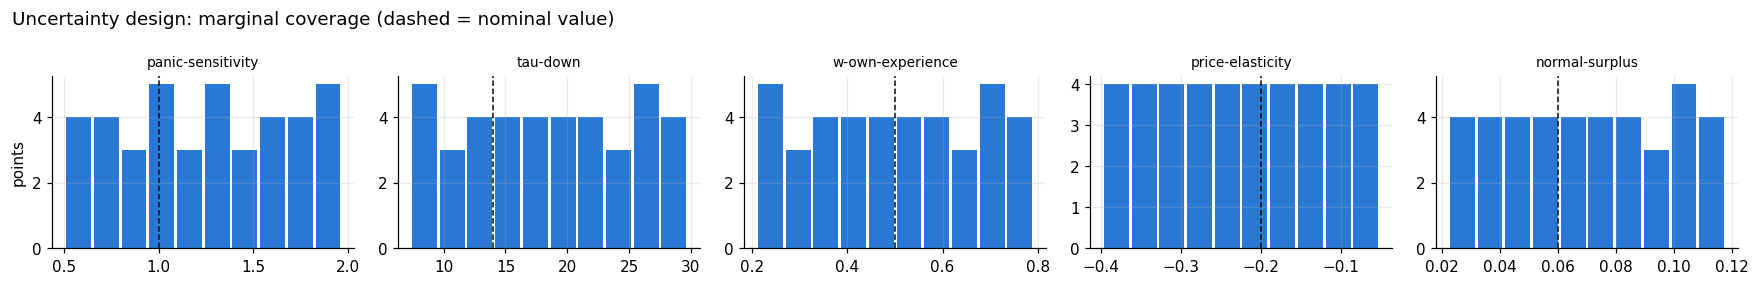

In [7]:
def lhs_maximin(n, d, rng, n_cand=N_CAND):
    """This function generates a Latin Hypercube Sample (LHS) with a maximin criterion.
    It creates n points in d dimensions, ensuring that the minimum distance between any two points is maximized.
    The function uses a random number generator (rng) to create candidate samples
    and selects the one with the largest minimum distance.
    
    Parameters:
        n (int): Number of points to generate.
        d (int): Number of dimensions.
        rng (np.random.Generator): A random number generator instance.
        n_cand (int): Number of candidate samples to generate for the maximin criterion.
    
    Returns:
        best (np.ndarray): The best LHS sample with the largest minimum distance.
        best_d (float): The minimum distance of the best sample.
    
    """
    
    best, best_d = None, -1
    for _ in range(n_cand):
        u = np.column_stack([(rng.permutation(n) + rng.random(n)) / n for _ in range(d)])
        dmin = pdist(u).min()
        if dmin > best_d:
            best, best_d = u, dmin
    return best, best_d

u, dmin = lhs_maximin(N_U, len(UNC_NAMES), np.random.default_rng(LHS_SEED))
UPTS = pd.DataFrame({k: UNC[k][0] + u[:, i] * (UNC[k][1] - UNC[k][0]) for i, k in enumerate(UNC_NAMES)})
UPTS.insert(0, "u_id", [f"U{i + 1:02d}" for i in range(N_U)])
UPTS.to_csv(OUT_DIR / "design_robust_points.csv", index=False, encoding="utf-8-sig")
print(f"{N_U} uncertainty points, min distance {dmin:.3f}")

fig, axes = plt.subplots(1, len(UNC_NAMES), figsize=(16, 2.6))
for ax, k in zip(axes, UNC_NAMES):
    ax.hist(UPTS[k], bins=10, color=PAL[0], rwidth=0.9)
    ax.axvline(PREP["nominal_uncertain"][k], color="#0b0b0b", lw=1, ls="--")
    ax.set_title(k, fontsize=9)
axes[0].set_ylabel("points")
fig.suptitle("Uncertainty design: marginal coverage (dashed = nominal value)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

In [8]:
def make_job(sname, upt, shock, seed, rep):
    """This function constructs the parameters for the simulation based on the point's lever settings and the specified shock
    
    Parameters:
        sname (str): The name of the strategy.
        upt (pandas.Series): A row from the UPTS DataFrame containing the point's settings.
        shock (float): The shock level to be applied in the simulation.
        seed (int): The random seed for the simulation run.
        rep (int): The repetition number for the simulation run.
        
    Returns:
        dict: A dictionary containing the run ID, stage, strategy name, uncertainty point ID, shock level, seed, repetition number, parameters for the simulation, and uncertain parameters.
    
    """

    unc = {k: float(getattr(upt, k.replace("-", "_"))) for k in UNC_NAMES}
    return {"run_id": f"robust|{sname}|{upt.u_id}|sd={shock}|seed={seed}", "stage": "robust",
            "strategy": sname, "u_id": upt.u_id, "shock": shock, "seed": int(seed), "rep": rep,
            "params": STRATS[sname]["params"] | {"shock-depth": shock}, "uncertain": unc}

UP = UPTS.rename(columns=lambda c: c.replace("-", "_"))
JOBS = [make_job(s, up, sh, sd, r)
        for r, sd in enumerate(SEEDS_RB, 1) for sh in SHOCKS for up in UP.itertuples() for s in STRATS]


In [9]:
DESIGN = pd.DataFrame([{k: v for k, v in j.items() if k not in ("params", "uncertain")} for j in JOBS])
assert DESIGN.run_id.is_unique
DESIGN.to_csv(OUT_DIR / "design_robust.csv", index=False, encoding="utf-8-sig")
sec = LVS["sec_per_run_mean"]
print(f"jobs: {len(JOBS)} | estimated time at ~{sec:.0f}-{sec * 1.2:.0f} s/run on {N_WORKERS} workers: "
      f"~{len(JOBS) * sec / N_WORKERS / 3600:.1f}-{len(JOBS) * sec * 1.2 / N_WORKERS / 3600:.1f} h")

jobs: 2640 | estimated time at ~15-18 s/run on 2 workers: ~5.4-6.5 h


## 3.3. Launching

In [6]:
# ! WARNING This cell takes approximately 360 minutes to run (2640 runs on 2 workers)
link = ar.make_link(CFG) if N_WORKERS == 1 else None
RES = br.run_jobs(JOBS, CFG, OUT_DIR / "robust.csv", n_workers=N_WORKERS, link=link, log_every=60)
print(RES.groupby("shock").size().rename("runs"))

22:31:51 start: 2640 runs, workers: 2
22:32:56 9/2640 | 1 min | 496 runs/h | ETA ~318 min | errors 0
22:34:05 21/2640 | 2 min | 562 runs/h | ETA ~280 min | errors 0
22:35:06 32/2640 | 3 min | 591 runs/h | ETA ~265 min | errors 0
22:36:11 39/2640 | 4 min | 539 runs/h | ETA ~290 min | errors 0
22:37:15 47/2640 | 5 min | 521 runs/h | ETA ~298 min | errors 0
22:38:22 55/2640 | 7 min | 506 runs/h | ETA ~306 min | errors 0
22:39:25 63/2640 | 8 min | 499 runs/h | ETA ~310 min | errors 0
22:40:34 71/2640 | 9 min | 489 runs/h | ETA ~315 min | errors 0
22:41:35 78/2640 | 10 min | 481 runs/h | ETA ~320 min | errors 0
22:42:45 85/2640 | 11 min | 468 runs/h | ETA ~328 min | errors 0
22:43:56 91/2640 | 12 min | 452 runs/h | ETA ~339 min | errors 0
22:45:08 97/2640 | 13 min | 438 runs/h | ETA ~348 min | errors 0
22:46:25 103/2640 | 15 min | 424 runs/h | ETA ~359 min | errors 0
22:47:35 111/2640 | 16 min | 423 runs/h | ETA ~359 min | errors 0
22:48:38 119/2640 | 17 min | 425 runs/h | ETA ~356 min | er

## 3.4. Check missing

In [10]:
RES = br.read_results(OUT_DIR / "robust.csv")
RES = RES[RES.run_id.isin(DESIGN.run_id)].copy()
print(f"completed {len(RES)} of {len(DESIGN)}, missing {len(DESIGN) - len(RES)}")
print("error file:", "present - check it" if (OUT_DIR / "robust.errors.csv").exists() else "none")
print("runs per seed:", RES.groupby("seed").size().to_dict())
print(f"run time: mean {RES.sec.mean():.1f} s, median {RES.sec.median():.1f} s, max {RES.sec.max():.1f} s")
full = RES.groupby(["u_id", "shock", "seed"]).strategy.nunique()
full = full[full == len(STRATS)].index
RES = RES.set_index(["u_id", "shock", "seed"]).loc[full].reset_index()
print(f"complete scenarios: {len(full)} of {N_U * len(SHOCKS) * R}")

completed 2640 of 2640, missing 0
error file: none
runs per seed: {262: 1320, 611: 1320}
run time: mean 16.8 s, median 16.3 s, max 40.9 s
complete scenarios: 240 of 240


## 3.5. Response, normalization and regret

This section evaluates and compares the performance of different strategies across uncertainty scenarios by calculating normalized performance scores and regret. It also checks whether each strategy satisfies all predefined performance and cost thresholds, enabling the identification of effective and robust strategies.

In [11]:
# use the same four axis defined in 02 leveling
AXES = ["K0", "K4", "K5_excess", "COST"]
# excess queues above background
RES["K5_excess"] = (RES.K5_hours - K5_BG) / N_CARS  
RES["COST"] = RES.K2 + C3_NOM * RES.K3_volume

# group by three parameters: uncertainty point, shock, seed
key = ["u_id", "shock", "seed"]
none = RES.loc[RES.strategy == "none", key + ["K0", "K4"]].rename(columns={"K0": "K0_none", "K4": "K4_none"})
RES = RES.merge(none, on=key, how="left")
RES["K0_rel"] = RES.K0 / RES.K0_none.clip(lower=1)
RES["K4_rel"] = RES.K4 / RES.K4_none
g = RES.groupby(key)


for a in AXES:
    # min–max normalization within each scenario
    # (uncertainty point + shock + seed)
    # 0 - best, 1 - worst
    lo, hi = g[a].transform("min"), g[a].transform("max")
    RES["n_" + a] = ((RES[a] - lo) / (hi - lo).replace(0, np.nan)).fillna(0)

# now everything is normalized and we can calculate the score and regret
RES["score"] = RES[["n_" + a for a in AXES]].mean(axis=1)
# distance from the best score in the same scenario (uncertainty point + shock + seed)
RES["score_regret"] = RES.score - RES.groupby(key).score.transform("min")
# does the strategy pass all four thresholds?
RES["pass_all"] = ((RES.K0_rel <= THRESH["K0_rel"]) & (RES.K4_rel <= THRESH["K4_rel"]) &
                   (RES.K5_excess <= THRESH["K5_excess"]) & (RES.COST <= THRESH["COST"]))
RES = RES.merge(UPTS, on="u_id", how="left", suffixes=("", "_u"))
RES.to_csv(OUT_DIR / "robust_scored.csv", index=False, encoding="utf-8-sig")
print("scored rows:", len(RES))

scored rows: 2640


## 3.6. Summary table of robustness

In [ ]:
def p90(x):
    """This function calculates the 90th percentile of a given array-like input."""
    return np.quantile(x, 0.9)

# aggregate the results by four axis, score, regret and pass_all
agg = {"K0_rel": ["mean", p90], "K4_rel": ["mean", p90], "K5_excess": ["mean", p90], "COST": ["mean", p90],
       "score": ["mean", p90], "score_regret": ["mean", "max"], "pass_all": "mean"}

# group by shock and strategy to aggregate the results
SUM = RES.groupby(["shock", "strategy"]).agg(agg)
SUM.columns = [f"{a}_{b if isinstance(b, str) else 'p90'}" for a, b in SUM.columns]
SUM = SUM.rename(columns={"pass_all_mean": "pass_share"}).reset_index()
SUM["strategy"] = pd.Categorical(SUM.strategy, categories=list(STRATS), ordered=True)
SUM = SUM.sort_values(["shock", "strategy"])
SUM.to_csv(OUT_DIR / "robust_summary_table.csv", index=False, encoding="utf-8-sig")
for sh in SHOCKS:
    print(f"\n=== shock-depth = {sh} ===")
    display(SUM[SUM.shock == sh].drop(columns="shock").set_index("strategy").round(3))


=== shock-depth = 0.2 ===


,K0_rel_mean,K0_rel_p90,K4_rel_mean,K4_rel_p90,K5_excess_mean,K5_excess_p90,COST_mean,COST_p90,score_mean,score_p90,score_regret_mean,score_regret_max,pass_share
strategy,,,,,,,,,,,,,
S1,0.027,0.076,0.174,0.286,0.667,0.485,64678.096,79537.722,0.109,0.173,0.013,0.340,0.925
S2,0.029,0.039,0.088,0.156,0.676,0.637,94750.991,109022.414,0.128,0.181,0.032,0.268,0.912
S3,0.012,0.032,0.174,0.283,0.858,1.604,62473.899,76887.649,0.112,0.182,0.016,0.259,0.950
S4,0.015,0.001,0.103,0.173,0.752,0.588,150182.327,160075.200,0.165,0.221,0.069,0.400,0.962
S5,0.029,0.084,0.190,0.335,1.569,3.742,108199.929,112055.116,0.172,0.255,0.075,0.334,0.875
S6,0.026,0.002,0.163,0.289,0.821,0.541,91089.232,104567.502,0.132,0.203,0.035,0.317,0.925
S7,0.022,0.000,0.002,0.004,0.907,1.267,363132.278,375625.659,0.404,0.500,0.308,0.559,0.000
S8,0.018,0.000,0.144,0.243,0.262,0.507,92600.145,107557.182,0.120,0.181,0.024,0.198,0.962
S9,0.011,0.002,0.166,0.288,0.990,1.224,91748.450,106418.177,0.133,0.189,0.037,0.395,0.950



=== shock-depth = 0.45 ===


,K0_rel_mean,K0_rel_p90,K4_rel_mean,K4_rel_p90,K5_excess_mean,K5_excess_p90,COST_mean,COST_p90,score_mean,score_p90,score_regret_mean,score_regret_max,pass_share
strategy,,,,,,,,,,,,,
S1,0.089,0.198,0.142,0.232,1.970,4.937,168324.195,185488.304,0.164,0.215,0.015,0.303,0.638
S2,0.190,0.429,0.043,0.074,4.618,13.490,183183.746,195571.492,0.235,0.360,0.085,0.288,0.338
S3,0.323,0.979,0.124,0.213,19.255,56.490,122958.500,126106.376,0.330,0.547,0.181,0.470,0.312
S4,0.093,0.271,0.240,0.377,3.270,10.464,198603.095,207139.606,0.232,0.329,0.083,0.420,0.675
S5,0.265,0.884,0.199,0.347,21.964,68.063,107486.392,110364.773,0.350,0.536,0.201,0.465,0.475
S6,0.089,0.229,0.222,0.331,4.014,13.171,142679.231,148916.527,0.199,0.266,0.050,0.290,0.650
S7,0.025,0.057,0.122,0.194,2.747,7.044,412095.993,422061.678,0.326,0.423,0.177,0.299,0.000
S8,0.069,0.154,0.082,0.142,2.195,5.447,202863.658,222455.907,0.180,0.249,0.031,0.212,0.762
S9,0.064,0.181,0.237,0.351,3.571,11.759,161086.384,172314.876,0.198,0.264,0.049,0.356,0.762



=== shock-depth = 0.7 ===


,K0_rel_mean,K0_rel_p90,K4_rel_mean,K4_rel_p90,K5_excess_mean,K5_excess_p90,COST_mean,COST_p90,score_mean,score_p90,score_regret_mean,score_regret_max,pass_share
strategy,,,,,,,,,,,,,
S1,0.159,0.297,0.120,0.186,6.279,17.178,254671.789,268929.650,0.190,0.210,0.016,0.055,0.300
S2,1.427,2.789,0.028,0.046,91.270,168.576,195563.017,197152.010,0.357,0.468,0.184,0.305,0.012
S3,2.693,5.002,0.079,0.131,150.563,228.730,126375.000,126750.000,0.550,0.597,0.377,0.470,0.000
S4,0.144,0.310,0.257,0.380,12.490,30.143,192787.529,198742.070,0.196,0.233,0.023,0.136,0.312
S5,2.487,4.357,0.130,0.215,152.954,237.660,100723.360,103246.170,0.530,0.583,0.356,0.449,0.012
S6,0.385,0.886,0.240,0.329,54.897,155.458,143977.714,146522.357,0.248,0.399,0.074,0.237,0.125
S7,0.033,0.087,0.152,0.236,6.746,17.830,418929.992,431451.209,0.286,0.305,0.112,0.184,0.000
S8,0.142,0.288,0.055,0.088,7.044,16.057,304907.640,324279.926,0.203,0.222,0.029,0.064,0.125
S9,0.102,0.226,0.355,0.507,9.964,24.691,165474.022,171453.574,0.196,0.236,0.023,0.191,0.412


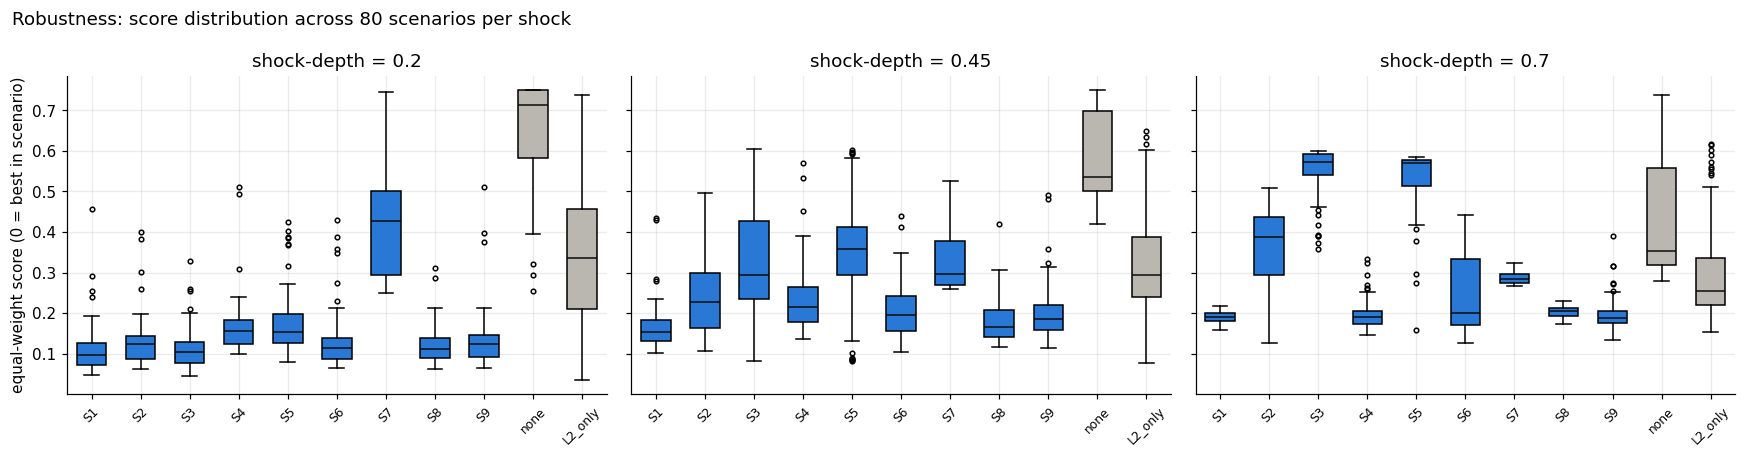

In [ ]:
# plot the distribution of equal-weight score
# across 80 scenarios per shock
names = list(STRATS)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, sh in zip(axes, SHOCKS):
    data = [RES[(RES.shock == sh) & (RES.strategy == s)].score.to_numpy() for s in names]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={"color": "#0b0b0b"},
                    flierprops={"markersize": 3})
    for patch, s in zip(bp["boxes"], names):
        patch.set_facecolor(GRAY if s in ("none", "L2_only") else PAL[0])
    ax.set_xticks(range(1, len(names) + 1), names, rotation=45, fontsize=8)
    ax.set_title(f"shock-depth = {sh}")
axes[0].set_ylabel("equal-weight score (0 = best in scenario)")
fig.suptitle("Robustness: score distribution across 80 scenarios per shock", x=0.01, ha="left")
plt.tight_layout(); plt.show()


Runs split in 3 shock levels, each box represents the performance of 11 strategies being run by 80 scenarios (40 points × 2 seed) - x axis.
Equal-weight score (0 - best, 1 - worst so the lower the score) is the y axis

Note: 0 score means that the strategy is the best in this scenario, not that it has the best absolute performance in the model. 

Similar to the Pareto front results during leveling, we can see the growth of strategies performance distribution growing as the shock level increases. Unsurprisingly, the "no measures" strategy is the worst in all scenarios, while the "L2 only" strategy has a wide range of performance, from good to poor quality.

- Shock-level = 0.2: S1, S2, S3, S6, S8 and S9 all perform well with small spread characterized by the size their boxes, while S7 visibly underperforms
- Shock-level = 0.45 is where scenarios start to diverge with S1 getting best results and S8, S9 following after. We also see how spread is growing especially noticeable for S3, S2 and S5
- Shock-level = 0.7 has the most divergence in terms of performance and spread with S1 being the most thin box-plot through whole range of scenarios and S6 being sometimes being the best and sometimes being not good at all. We also can see how the whole equal-weighted score level has shifted up, meaning that all strategies are performing worse than in previous shock levels.   

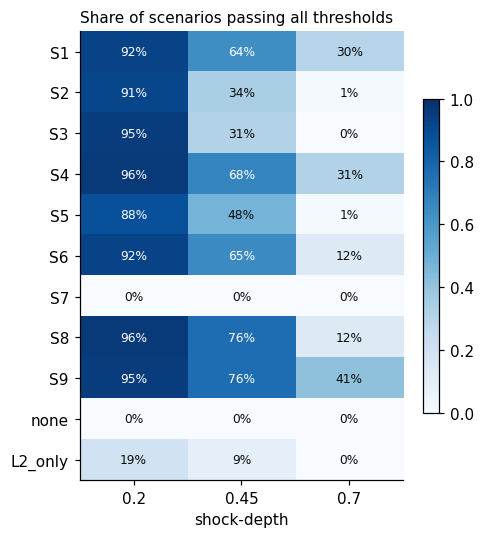

In [ ]:
# aggregate the results by shock and strategy
# to visualize the share of scenarios passing all thresholds
ps = SUM.pivot(index="strategy", columns="shock", values="pass_share").reindex(names)
fig, ax = plt.subplots(figsize=(4.6, 5))
im = ax.imshow(ps.to_numpy(float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(SHOCKS)), [str(s) for s in SHOCKS]); ax.set_yticks(range(len(names)), names)
for i in range(ps.shape[0]):
    for j in range(ps.shape[1]):
        v = ps.iat[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else "#0b0b0b")
ax.set_xlabel("shock-depth"); ax.grid(False)
ax.set_title("Share of scenarios passing all thresholds", loc="left", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.7); plt.tight_layout(); plt.show()

No measures and S7 strategy never passes thresholds

During shock 0.2 almost all strategies are passing thresholds in 88–96% scenarios, then only S8 and S9 perform well enough (76%) in 0.45 shock, with S4 S6 and S1 catching up. In shock 0.7 no one passes thresholds in more than 50% of scenarios, with S9 being the best by a significant margin at 41%. 

The fact that both S1 and S9 win during the 0.7 shock is no surprising since we compare different criteria: box-plot is about the equal-weighted score, while the heatmap is about the share of scenarios passing all thresholds specified at the beginning of the 03 notebook. Once again, it shows that the choice of the best strategy depends on the criteria we use to evaluate it


### Compromises across axes

Averages across 80 scenarios: deficit and surplus relative to "no measures", queues and costs - in original units; whiskers - from 10th to 90th percentile. Dashed line - threshold.

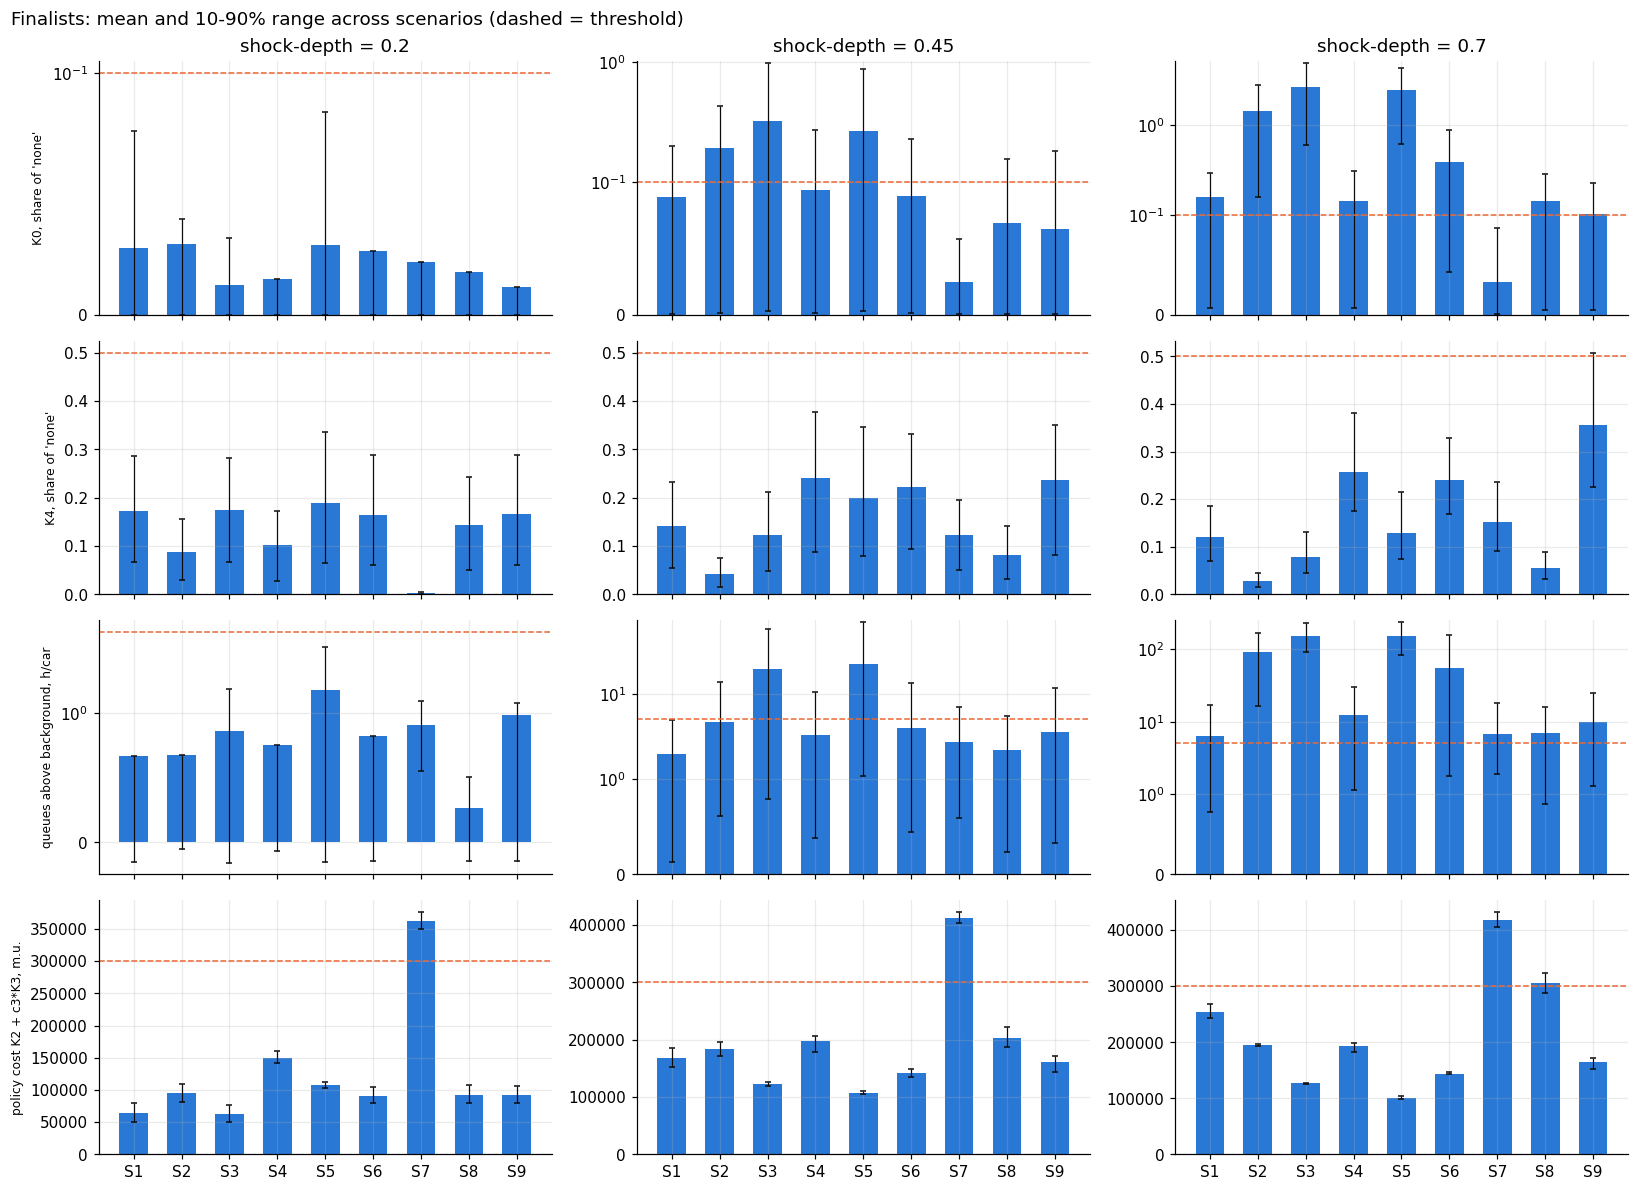

In [16]:
fin = [s for s in names if s not in ("none", "L2_only")]
cols = [("K0_rel", "K0, share of 'none'"), ("K4_rel", "K4, share of 'none'"),
        ("K5_excess", "queues above background, h/car"), ("COST", "policy cost K2 + c3*K3, m.u.")]
fig, axes = plt.subplots(len(cols), 3, figsize=(15, 11), sharex=True)
for j, sh in enumerate(SHOCKS):
    d = RES[(RES.shock == sh) & RES.strategy.isin(fin)]
    for i, (c, lab) in enumerate(cols):
        ax = axes[i, j]
        q = d.groupby("strategy")[c].quantile([0.1, 0.5, 0.9]).unstack().reindex(fin)
        m = d.groupby("strategy")[c].mean().reindex(fin)
        x = np.arange(len(fin))
        ax.bar(x, m, color=PAL[0], width=0.6)
        ax.errorbar(x, m, yerr=[(m - q[0.1]).clip(lower=0), (q[0.9] - m).clip(lower=0)], fmt="none",
                    ecolor="#0b0b0b", elinewidth=0.8, capsize=2)
        ax.axhline(THRESH[c], color=PAL[1], lw=1, ls="--")
        if c in ("K0_rel", "K5_excess"):
            ax.set_yscale("symlog", linthresh=0.1 if c == "K0_rel" else 1)
        if j == 0: ax.set_ylabel(lab, fontsize=8)
        if i == 0: ax.set_title(f"shock-depth = {sh}")
        ax.set_xticks(x, fin)
fig.suptitle("Finalists: mean and 10-90% range across scenarios (dashed = threshold)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

With X axis being the strategies and Y axis being the four axes of performance, we can see how different strategies perform across different criteria. The dashed line indicates the threshold for each axis, allowing us to visually assess which strategies meet the acceptable performance levels. The blue bars represent the mean for each strategy - the lower the bar, the better the performance

We will go through four axes to see how different strategies perform across shock levels. Here we have higher number of plots so we focus on higher levels of shock. In 0.2 shock only S7 underperforms for the policy cost criteria
- K0 deficit: for 0.45 shock S1, S4, S6, S7, S8 and S9 are lower but most of them have whiskers above the threshold, meaning that in some scenarios they are not performing well enough.  with 0.7 shock only S7 performs well and S9 has its border right at the threshold.
- Overpay K4: all strategies are lower the 50% threshold, no matter the shock. Only the S9 whisker under 0.7 shock barely touches it
- Queues above background: for shock 0.45 all mean below threshold (some whiskers stand out) except for S3 and S5. Shock 0.7 does not have any strategy with mean below threshold, but S1, S7 and S8 are closest to it
- Policy cost: for shock 0.45 everything is below threshold except for S7 (huge expenditure), while for shock 0.7 S8 also becomes a budget problem with mean closing in on the threshold and whiskers extending further, catching up with S7 which is still most expensive one

## 3.7. Stage results

1. **Strategy under shock** - the lowest 90th percentile of the score under this shock (for comparison - the share of scenarios where all thresholds are met);
2. **One stable strategy** - the lowest worst 90th percentile of the score across three shocks.


In [17]:
FS = SUM[SUM.strategy.isin(fin)].copy()
ans1 = (FS.sort_values(["shock", "score_p90"]).groupby("shock").head(1)
        [["shock", "strategy", "score_p90", "score_mean", "pass_share", "K0_rel_mean", "K4_rel_mean",
          "K5_excess_mean", "COST_mean"]])
ans1["point_id"] = ans1.strategy.map(lambda s: STRATS[s]["point_id"])
best_pass = FS.sort_values(["shock", "pass_share", "score_p90"], ascending=[True, False, True]).groupby("shock").head(1)
print("Answer 1 - best strategy for each shock (min P90 of equal-weight score):")
display(ans1.round(3))
print("Alternative criterion - highest share of scenarios passing all thresholds:")
display(best_pass[["shock", "strategy", "pass_share", "score_p90"]].round(3))

worst = FS.groupby("strategy", observed=True).score_p90.max().sort_values()
ROBUST = worst.index[0]
print(f"Answer 2 - single robust strategy: {ROBUST} ({STRATS[ROBUST]['point_id']}, "
      f"{STRATS[ROBUST]['role']}), worst-shock P90 score = {worst.iloc[0]:.3f}")
display(worst.rename("worst P90 score across shocks").to_frame().round(3))

cross = SUM.pivot(index="strategy", columns="shock", values="score_p90").loc[ans1.strategy.unique()]
print("Misjudged shock: P90 score of each shock-specific choice under every actual shock:")
display(cross.round(3))

Answer 1 - best strategy for each shock (min P90 of equal-weight score):


,shock,strategy,score_p90,score_mean,pass_share,K0_rel_mean,K4_rel_mean,K5_excess_mean,COST_mean,point_id
1,0.20,S1,0.173,0.109,0.925,0.027,0.174,0.667,64678.096,A31
12,0.45,S1,0.215,0.164,0.638,0.089,0.142,1.970,168324.195,A31
23,0.70,S1,0.210,0.190,0.300,0.159,0.120,6.279,254671.789,A31


Alternative criterion - highest share of scenarios passing all thresholds:


,shock,strategy,pass_share,score_p90
8,0.20,S8,0.962,0.181
19,0.45,S8,0.762,0.249
31,0.70,S9,0.412,0.236


Answer 2 - single robust strategy: S1 (A31, best worst-case score across shocks), worst-shock P90 score = 0.215


,worst P90 score across shocks
strategy,
S1,0.215
S8,0.249
S9,0.264
S4,0.329
S6,0.399
S2,0.468
S7,0.500
S5,0.583
S3,0.597


Misjudged shock: P90 score of each shock-specific choice under every actual shock:


shock,0.20,0.45,0.70
strategy,,,
S1,0.173,0.215,0.21


## 3.8. Sensitivity: PRCC

PRCC (partial rank correlation coefficient) is a measure of the correlation between a parameter and the response variable after removing the linear influence of other parameters. It ranges from -1 to +1, where the sign indicates the direction of the relationship:
- PRCC ≈ +1 means a strong positive relationship: as Xᵢ increases, Y also increases.
- PRCC ≈ −1 means a strong negative relationship: as Xᵢ increases, Y decreases.
- PRCC ≈ 0 means that the parameter does not significantly affect the response or the effect is non-monotonic - then PRCC will not detect it.

Why we need PRCC? It helps us understand which uncertain parameters have the most influence on the performance of the strategies. By identifying these key parameters, we can focus our attention on managing or mitigating their effects, leading to more robust decision-making.


In [19]:
def prcc(X, y):
    """
    This function calculates the Partial Rank Correlation Coefficients (PRCC) between a set of independent variables (X) and a dependent variable (y).
    
    Parameters:
        X (numpy.ndarray): A 2D array where each column represents an independent variable.
        y (numpy.ndarray): A 1D array representing the dependent variable.
        
    Returns:
        list: A list of PRCC values for each independent variable in X.
    
    """
    
    Xr = np.column_stack([stats.rankdata(X[:, j]) for j in range(X.shape[1])])
    yr = stats.rankdata(y)
    out = []
    for j in range(X.shape[1]):
        Z = np.column_stack([np.ones(len(yr)), np.delete(Xr, j, axis=1)])
        rx = Xr[:, j] - Z @ np.linalg.lstsq(Z, Xr[:, j], rcond=None)[0]
        ry = yr - Z @ np.linalg.lstsq(Z, yr, rcond=None)[0]
        out.append(np.corrcoef(rx, ry)[0, 1] if rx.std() > 0 and ry.std() > 0 else np.nan)
    return out

rows = []
for (sh, s), d in RES.groupby(["shock", "strategy"]):
    X = d[UNC_NAMES].to_numpy(float)
    for resp in ["K0", "K4", "K5_excess", "COST", "score"]:
        for name, v in zip(UNC_NAMES, prcc(X, d[resp].to_numpy(float))):
            rows.append({"shock": sh, "strategy": s, "response": resp, "parameter": name, "PRCC": v})
PRCC = pd.DataFrame(rows)
PRCC.to_csv(OUT_DIR / "robust_prcc.csv", index=False, encoding="utf-8-sig")


imp = (PRCC[PRCC.strategy.isin(fin)].assign(absP=lambda d: d.PRCC.abs())
       .groupby(["response", "parameter"]).absP.mean().unstack().reindex(columns=UNC_NAMES))
print("Mean |PRCC| across finalists and shocks (which assumptions matter most):")
display(imp.round(2))


Mean |PRCC| across finalists and shocks (which assumptions matter most):


parameter,panic-sensitivity,tau-down,w-own-experience,price-elasticity,normal-surplus
response,,,,,
COST,0.28,0.16,0.25,0.34,0.60
K0,0.56,0.11,0.49,0.28,0.40
K4,0.34,0.21,0.31,0.56,0.62
K5_excess,0.61,0.19,0.52,0.45,0.31
score,0.24,0.16,0.18,0.59,0.39


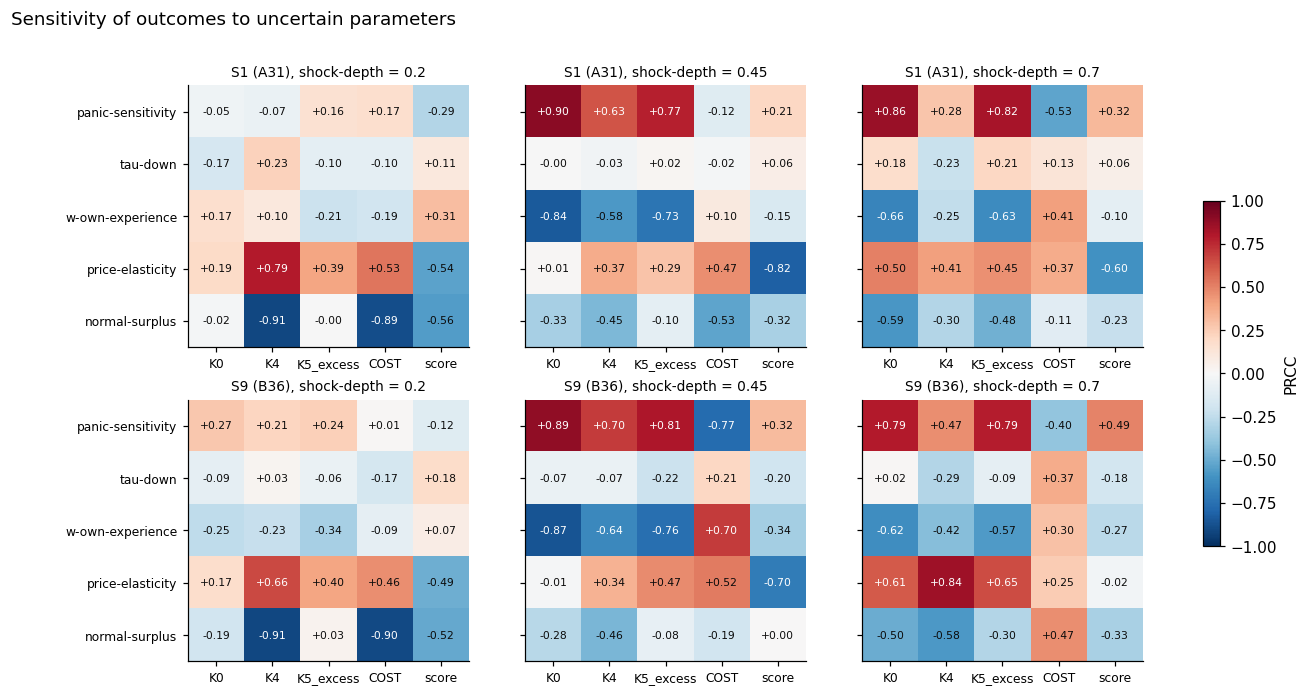

In [ ]:
show = [ROBUST] + (["S9"] if ROBUST != "S9" else [])
resps = ["K0", "K4", "K5_excess", "COST", "score"]
fig, axes = plt.subplots(len(show), 3, figsize=(
    14, 3.4 * len(show)), squeeze=False)
for i, s in enumerate(show):
    for j, sh in enumerate(SHOCKS):
        ax = axes[i, j]
        M = PRCC.query("strategy == @s and shock == @sh").pivot(index="parameter", columns="response",
                                                                values="PRCC").reindex(index=UNC_NAMES, columns=resps)
        im = ax.imshow(M.to_numpy(float), cmap="RdBu_r",
                       vmin=-1, vmax=1, aspect="auto")
        ax.set_xticks(range(len(resps)), resps, fontsize=8)
        ax.set_yticks(range(len(UNC_NAMES)), UNC_NAMES, fontsize=8)
        ax.set_yticks(range(len(UNC_NAMES)),
                      UNC_NAMES if j == 0 else [], fontsize=8)
        for a in range(M.shape[0]):
            for b in range(M.shape[1]):
                v = M.iat[a, b]
                if np.isfinite(v):

                    ax.text(b, a, f"{v:+.2f}", ha="center", va="center", fontsize=7,
                            color="white" if abs(v) > 0.6 else "#0b0b0b")
        ax.grid(False)
        ax.set_title(
            f"{s} ({STRATS[s]['point_id']}), shock-depth = {sh}", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.6, label="PRCC")
fig.suptitle("Sensitivity of outcomes to uncertain parameters",
             x=0.01, ha="left")
plt.show()

We can see that no matter what the shock level is, the most influential parameters are panic-sensitivity and price-elasticity, which have the highest absolute PRCC values across all responses. Speaking of price-elasticity, we can look at shock 0.7 and see how price cap helps deal with price volatility. Without the cap (S9, B36) the overpay is mostly defined by how the demand reacts to the unconstrained price. Price cap reduces that risk and makes this uncontrollable parameter less influential. 

tau-down has almost no influence: |PRCC| mostly < 0.25 on all shocks.

Overpayment and policy cost depend mainly on market parameters (price elasticity and the normal export surplus). 

## 3.9. Where strategies stop meeting thresholds


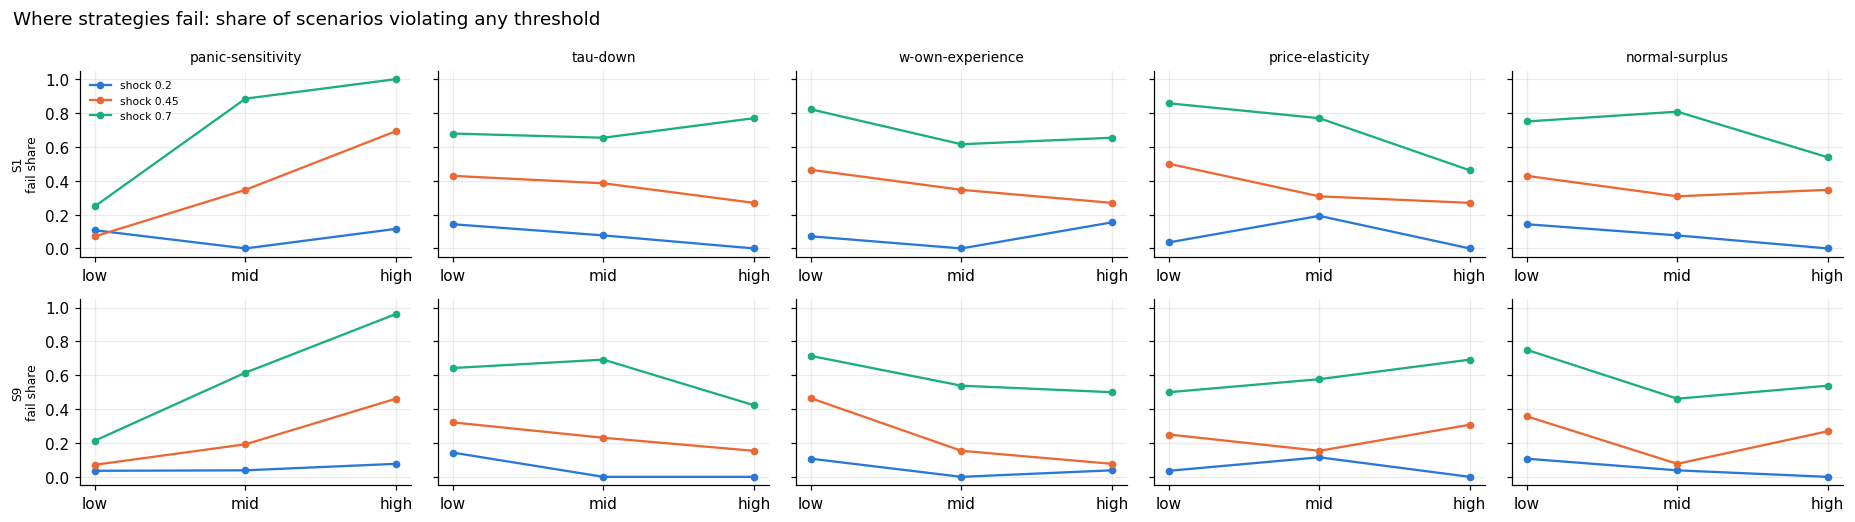

In [14]:
RES["fail"] = ~RES.pass_all
focus = list(dict.fromkeys([ROBUST, "S9"] + ans1.strategy.tolist()))
rows = []
for k in UNC_NAMES:
    RES[k + "_bin"] = pd.qcut(RES[k], 3, labels=["low", "mid", "high"])
    t = RES[RES.strategy.isin(focus)].groupby(["strategy", "shock", k + "_bin"], observed=True).fail.mean()
    for (s, sh, b), v in t.items():
        rows.append({"strategy": s, "shock": sh, "parameter": k, "bin": b, "fail_share": v})
FAIL = pd.DataFrame(rows)
FAIL.to_csv(OUT_DIR / "robust_fail_by_param.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(len(focus), len(UNC_NAMES), figsize=(17, 2.4 * len(focus)), sharey=True, squeeze=False)
for i, s in enumerate(focus):
    for j, k in enumerate(UNC_NAMES):
        ax = axes[i, j]
        for c, sh in zip(PAL[:3], SHOCKS):
            d = FAIL.query("strategy == @s and parameter == @k and shock == @sh")
            ax.plot(["low", "mid", "high"], d.set_index("bin").fail_share.reindex(["low", "mid", "high"]),
                    "-o", color=c, ms=4, label=f"shock {sh}")
        if i == 0: ax.set_title(k, fontsize=9)
        if j == 0: ax.set_ylabel(f"{s}\nfail share", fontsize=8)
        ax.set_ylim(-0.05, 1.05)
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Where strategies fail: share of scenarios violating any threshold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 3.10. Итог этапа

Сохраняется `robust_summary.json`: ответы, сводные метрики и стратегии для этапов 4–5. Пришлите вывод этой ячейки, сводную таблицу (3.6), ответы (3.7), таблицу средних |PRCC| (3.8) и рисунки 3.6 и 3.9.

In [15]:
SUMMARY = {
    "created": time.strftime("%Y-%m-%d %H:%M"), "model_sha256": sha, "R": R, "seeds": SEEDS_RB, "shocks": SHOCKS,
    "n_uncertainty_points": N_U, "unc_ranges": UNC, "thresholds": THRESH, "c3_nominal": C3_NOM,
    "n_runs": int(len(RES)), "sec_per_run_mean": float(RES.sec.mean()), "n_workers": N_WORKERS,
    "answer_per_shock": {str(r.shock): {"strategy": r.strategy, "point_id": r.point_id,
                                        "score_p90": float(r.score_p90), "pass_share": float(r.pass_share)}
                         for r in ans1.itertuples()},
    "robust_strategy": {"strategy": ROBUST, "point_id": STRATS[ROBUST]["point_id"],
                        "worst_shock_score_p90": float(worst.iloc[0])},
    "strategies": STRATS,
}
(OUT_DIR / "robust_summary.json").write_text(json.dumps(SUMMARY, indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps({k: SUMMARY[k] for k in ["n_runs", "sec_per_run_mean", "answer_per_shock", "robust_strategy"]},
                 indent=1, default=float))

{
 "n_runs": 2640,
 "sec_per_run_mean": 16.813808918106023,
 "answer_per_shock": {
  "0.2": {
   "strategy": "S1",
   "point_id": "A31",
   "score_p90": 0.17303760566935106,
   "pass_share": 0.925
  },
  "0.45": {
   "strategy": "S1",
   "point_id": "A31",
   "score_p90": 0.2149208398836198,
   "pass_share": 0.6375
  },
  "0.7": {
   "strategy": "S1",
   "point_id": "A31",
   "score_p90": 0.20972219536398332,
   "pass_share": 0.3
  }
 },
 "robust_strategy": {
  "strategy": "S1",
  "point_id": "A31",
  "worst_shock_score_p90": 0.2149208398836198
 }
}
